# **Project Name**

**Workplace Mental Health in the Tech Industry: An Exploratory Data Analysis**

##### **Project Type**
- Exploratory Data Analysis (EDA)

##### **Contribution**
- Individual project

##### **Analyst**
- Prajwal Veerendra H

# **Project Summary**

In this project, I explore survey responses about mental health and workplace experiences in the technology sector. Using Python, pandas, NumPy, Matplotlib, and Seaborn, I examine respondent demographics, treatment-seeking responses, family history, work interference, employer benefits, and perceptions of workplace support.

My goal is to move beyond describing individual columns and investigate how selected personal and workplace factors are associated with treatment-seeking responses. The notebook uses univariate, bivariate, and multivariate visualizations, with an explanation of each chart and its potential business relevance.

The data reflects the people who responded to this survey; it should not be treated as representative of every technology employee. The findings are descriptive and observational, so patterns in the charts do not establish cause and effect.

# **Project Repository**

Add the URL of your own GitHub repository here after publishing this notebook.

[Link](https://github.com/Prajwal-VH?tab=repositories&q=&type=&language=&sort=)

# **Problem Statement**

Technology employers need to understand how employees experience mental-health support at work. This analysis explores survey responses to identify patterns in treatment-seeking, reported work interference, family history, awareness of benefits, and perceived workplace consequences. The aim is to identify areas for further investigation—not to diagnose individuals or claim that one factor causes a mental-health outcome.

#### **Business Objective**

Use survey data to describe employee responses and explore associations between treatment-seeking and selected personal or workplace factors. Translate observed patterns into practical questions for HR and people leaders: Are support resources visible? Do employees feel safe seeking help? Are benefits and support options clearly communicated?

**Analytical questions**
- What does the respondent profile look like, and what data-quality limitations should be considered?
- How are treatment-seeking responses distributed across the sample?
- How do treatment-seeking responses compare across family history, work interference, employer benefits, and remote work?
- What do responses suggest about perceived consequences, anonymity, and workplace support?
- Which conclusions are supported by the charts, and what additional evidence would be needed for stronger claims?

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# **Let's Begin**

The notebook follows a consistent workflow: understand the dataset, prepare the data, explore patterns visually, and summarize practical implications and limitations.

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Portfolio Chart Theme — "Calm Focus"
# A consistent, accessible palette for this Mental Health in Tech EDA project.
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=["#167D8D", "#E07A5F", "#5B6C8F", "#81B29A", "#F2CC8F"]
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.facecolor": "#F7F8FA",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#D9E1E8",
    "axes.labelcolor": "#263238",
    "axes.titlecolor": "#17324D",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 10,
    "xtick.color": "#455A64",
    "ytick.color": "#455A64",
    "grid.color": "#E6EBEF",
    "grid.linewidth": 0.8,
    "legend.frameon": False,
    "font.family": "DejaVu Sans",
})

print("Calm Focus chart theme loaded: teal, coral, slate and soft neutral backgrounds.")

Calm Focus chart theme loaded: teal, coral, slate and soft neutral backgrounds.


### Dataset Loading

In [3]:
# Load Dataset
df = pd.read_csv('survey.csv')

### Dataset First View

In [4]:
# Dataset First Look
df.head()

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(df.shape)

(1259, 27)


### Dataset Information

In [6]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      744 non-null    str  
 5   self_employed              1241 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             995 non-null    str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_program           1259 non

#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print(df.duplicated().sum())

0


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print(df.isnull().sum())

Timestamp                       0
Age                             0
Gender                          0
Country                         0
state                         515
self_employed                  18
family_history                  0
treatment                       0
work_interfere                264
no_employees                    0
remote_work                     0
tech_company                    0
benefits                        0
care_options                    0
wellness_program                0
seek_help                       0
anonymity                       0
leave                           0
mental_health_consequence       0
phys_health_consequence         0
coworkers                       0
supervisor                      0
mental_health_interview         0
phys_health_interview           0
mental_vs_physical              0
obs_consequence                 0
comments                     1095
dtype: int64


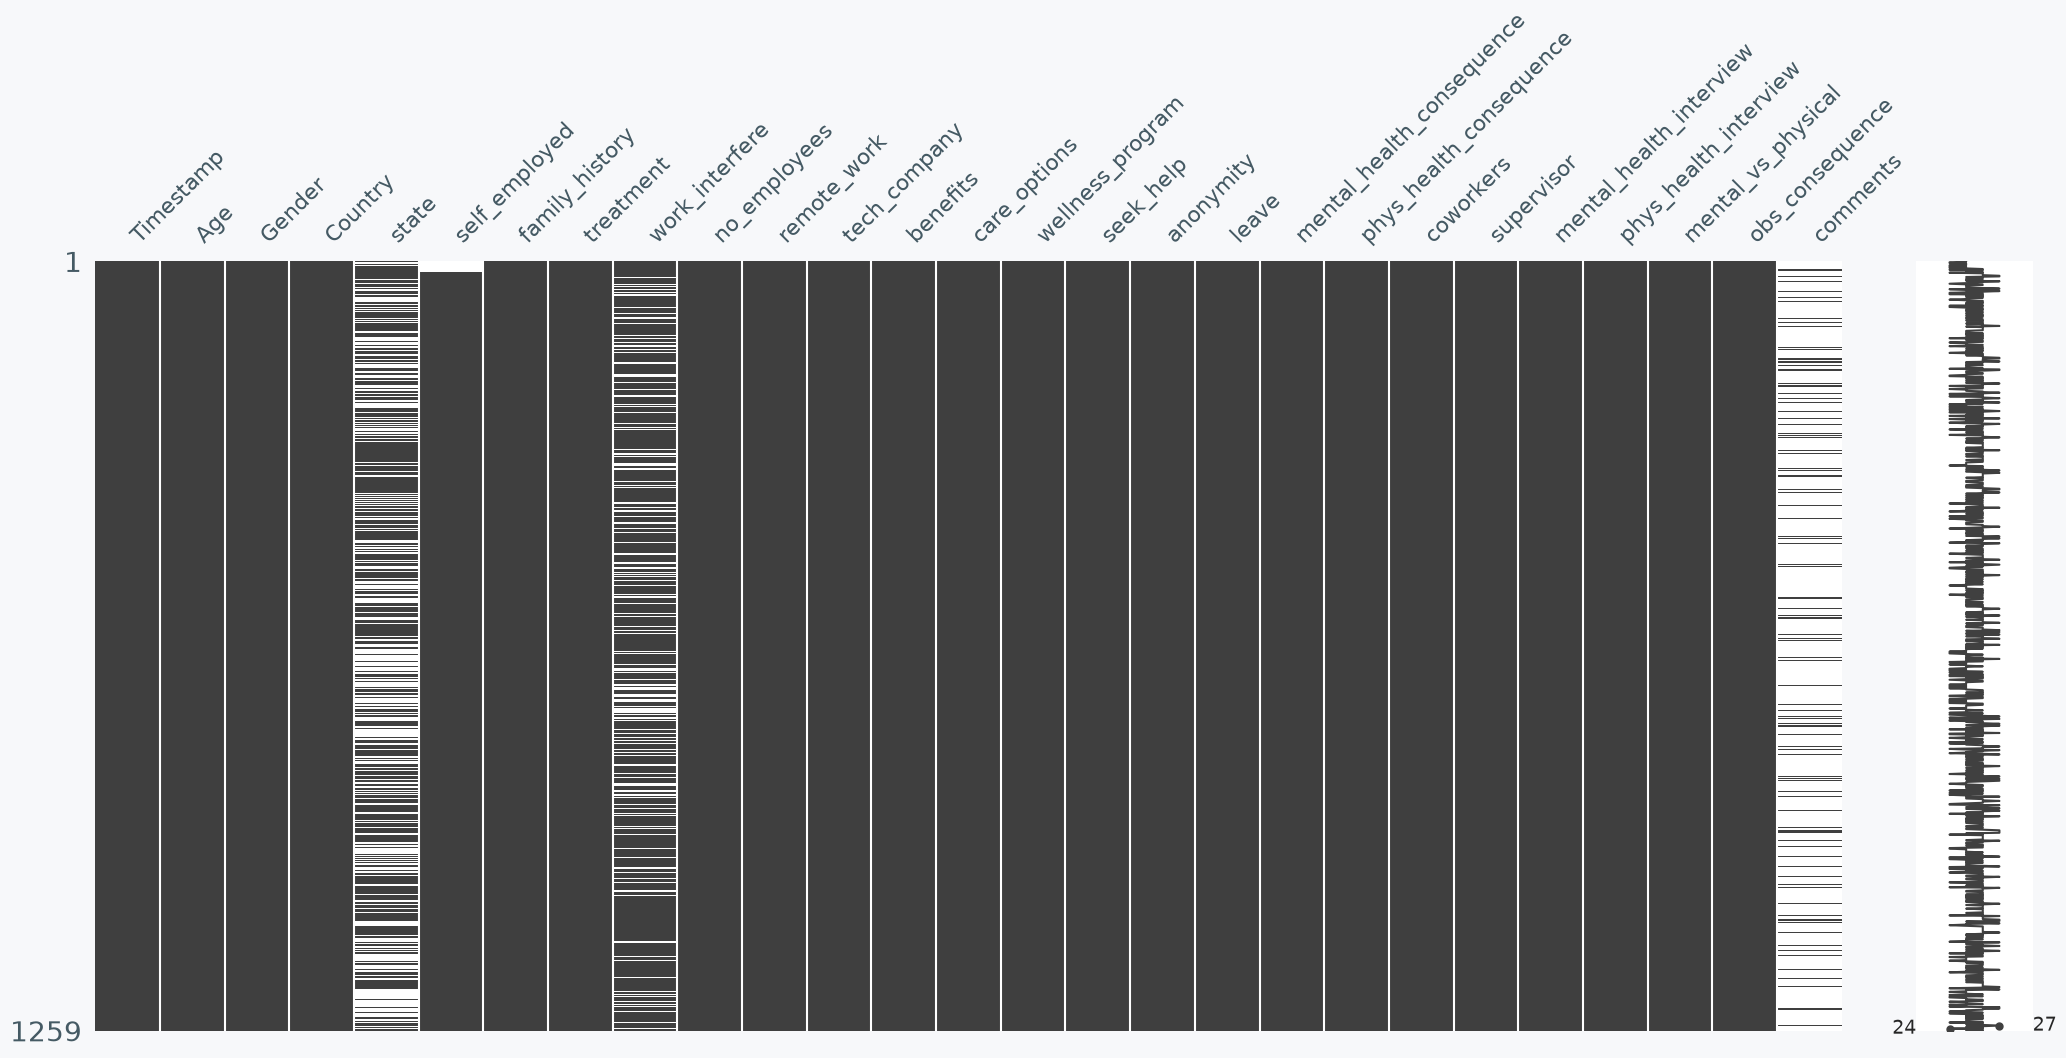

In [9]:
# Visualizing the missing values
msno.matrix(df)
plt.show()

### **Initial Data Understanding**

The notebook initially reports 1,259 rows and 27 columns. Most fields are categorical, while `Age` is numeric and `Timestamp` can be parsed as a date/time field if needed. Before interpreting charts, review missingness and unusual values and make the cleaning decisions transparent.

The survey is observational and self-reported. Results may be affected by who chose to respond, how questions were interpreted, and missing answers. These constraints should be considered throughout the analysis.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
list(df.columns)

['Timestamp',
 'Age',
 'Gender',
 'Country',
 'state',
 'self_employed',
 'family_history',
 'treatment',
 'work_interfere',
 'no_employees',
 'remote_work',
 'tech_company',
 'benefits',
 'care_options',
 'wellness_program',
 'seek_help',
 'anonymity',
 'leave',
 'mental_health_consequence',
 'phys_health_consequence',
 'coworkers',
 'supervisor',
 'mental_health_interview',
 'phys_health_interview',
 'mental_vs_physical',
 'obs_consequence',
 'comments']

In [11]:
# Dataset Describe
display(df.describe())
display(df.describe(include='object'))

,Age
count,1.259000e+03
mean,7.942815e+07
std,2.818299e+09
min,-1.726000e+03
25%,2.700000e+01
50%,3.100000e+01
75%,3.600000e+01
max,1.000000e+11


,Timestamp,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
count,1259,1259,1259,744,1241,1259,1259,995,1259,1259,...,1259,1259,1259,1259,1259,1259,1259,1259,1259,164
unique,1246,49,48,45,2,2,2,4,6,2,...,5,3,3,3,3,3,3,3,2,160
top,2014-08-27 12:31:41,Male,United States,CA,No,No,Yes,Sometimes,6-25,No,...,Don't know,No,No,Some of them,Yes,No,Maybe,Don't know,No,* Small family business - YMMV.
freq,2,615,751,138,1095,767,637,465,290,883,...,563,490,925,774,516,1008,557,576,1075,5


### Variables Description

### Variables Description
| Variable | Description |
|---|---|
| Timestamp | Survey submission time |
| Age | Respondent age |
| Gender | Respondent gender |
| Country | Respondent country |
| State | Respondent state |
| self_employed | Self-employed status |
| family_history | Family history of mental illness |
| treatment | Sought mental health treatment |
| work_interfere | Condition interferes with work |
| no_employees | Company employee count |
| remote_work | Works remotely >50% of the time |
| tech_company | Employer is a tech company |
| benefits | Mental health benefits provided |
| care_options | Knowledge of mental health care options |
| wellness_program | Mental health discussed in wellness program |
| seek_help | Resources provided to seek help |
| anonymity | Anonymity protected for treatment |
| leave | Ease of medical leave for mental health |
| mental_health_consequence | Negative consequences for discussing mental health |
| phys_health_consequence | Negative consequences for discussing physical health |
| coworkers | Willingness to discuss with coworkers |
| supervisor | Willingness to discuss with supervisor |
| mental_health_interview | Bring up mental health in an interview |
| phys_health_interview | Bring up physical health in an interview |
| mental_vs_physical | Employer takes mental health as seriously as physical |
| obs_consequence | Observed negative consequences for coworkers |
| comments | Additional comments |


### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].unique())


--- Timestamp ---
<ArrowStringArray>
['2014-08-27 11:29:31', '2014-08-27 11:29:37', '2014-08-27 11:29:44',
 '2014-08-27 11:29:46', '2014-08-27 11:30:22', '2014-08-27 11:31:22',
 '2014-08-27 11:31:50', '2014-08-27 11:32:05', '2014-08-27 11:32:39',
 '2014-08-27 11:32:43',
 ...
 '2015-07-22 18:57:54', '2015-07-27 23:25:34', '2015-08-17 09:38:35',
 '2015-08-20 16:52:09', '2015-08-25 19:59:38', '2015-09-12 11:17:21',
 '2015-09-26 01:07:35', '2015-11-07 12:36:58', '2015-11-30 21:25:06',
 '2016-02-01 23:04:31']
Length: 1246, dtype: str

--- Age ---
[         37          44          32          31          33          35
          39          42          23          29          36          27
          46          41          34          30          40          38
          50          24          18          28          26          22
          19          25          45          21         -29          43
          56          60          54         329          55 99999999999
          48 

## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
# 1. Standardize Gender
male_variants = ["male", "m", "male-ish", "maile", "mal", "male (cis)", "make", "male ", "man", "msle", "mail", "malr", "cis man", "cis male"]
female_variants = ["cis female", "f", "female", "woman",  "femake", "female ", "cis-female/femme", "female (cis)", "femail"]
df['Gender'] = df['Gender'].str.lower()
df['Gender'] = df['Gender'].apply(lambda x: "Male" if x in male_variants else ("Female" if x in female_variants else "Other"))

# 2. Fix Age
df = df[(df['Age'] >= 18) & (df['Age'] <= 80)].copy()

# 3. Fill nulls
df['self_employed'] = df['self_employed'].fillna(df['self_employed'].mode()[0])
df['work_interfere'] = df['work_interfere'].fillna(df['work_interfere'].mode()[0])

# 4. Drop columns
df.drop(columns=['Timestamp', 'State', 'comments'], inplace=True, errors='ignore')
df.reset_index(drop=True, inplace=True)

### **Data Preparation Decisions**

The preparation step standardizes common free-text variations in `Gender` into consistent categories and checks the age field for implausible values before analysis. These choices make categories easier to compare, but grouping free-text responses can simplify respondents' self-descriptions; any grouping should be documented and applied consistently.

Missing values should be handled according to the meaning of each field rather than automatically filling every blank. A blank response may mean that a question was not applicable or was left unanswered. Keep the original data available where possible, and verify the final row count and category values after cleaning.

## **4. Data Visualization, Storytelling, and Experimenting with Charts**

The charts examine the survey from several angles. For each chart, explain the choice of visualization, describe the pattern visible in the output, and connect it to a possible workplace implication. After running the notebook, verify each observation against the rendered chart; do not treat the patterns as proof of causation or generalize them to all technology employees.

#### Chart - 1

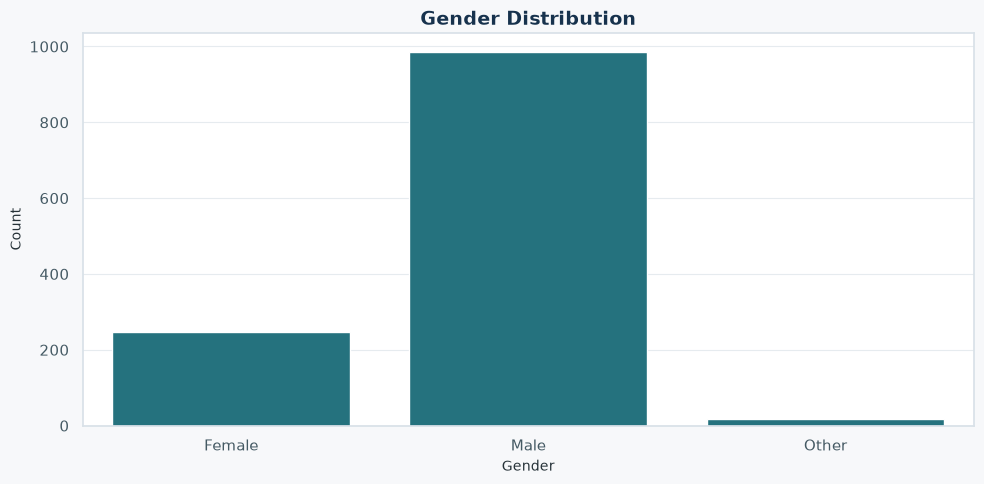

In [14]:
# Chart - 1 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Gender', color='#167D8D')
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is suitable because `Gender` is categorical and the goal is to compare the number of responses in each recorded category.

##### 2. What is/are the insight(s) found from the chart?

Use the displayed bar heights to identify which categories are most represented in this sample and which have fewer responses. This describes the survey composition, not the gender distribution of the entire technology workforce.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use the displayed bar heights to identify which categories are most represented in this sample and which have fewer responses. This describes the survey composition, not the gender distribution of the entire technology workforce.

#### Chart - 2

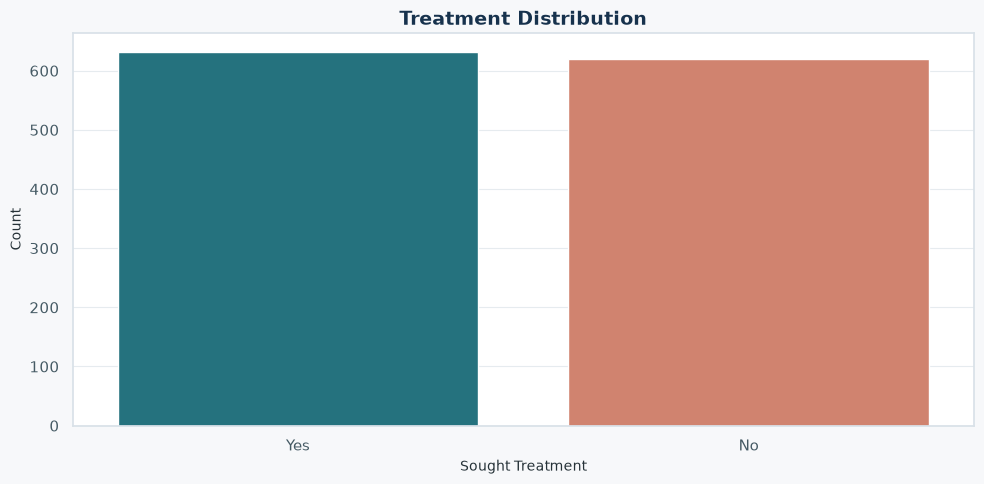

In [15]:
# Chart - 2 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='treatment', palette=['#167D8D', '#E07A5F'])
plt.title('Treatment Distribution')
plt.xlabel('Sought Treatment')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot makes the two recorded treatment responses easy to compare and gives a baseline for later subgroup analyses.

##### 2. What is/are the insight(s) found from the chart?

The taller bar indicates the more frequently selected response in this sample. Compare the counts with the number of valid responses; this is not an estimate of mental illness prevalence in the wider workforce.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The taller bar indicates the more frequently selected response in this sample. Compare the counts with the number of valid responses; this is not an estimate of mental illness prevalence in the wider workforce.

#### Chart - 3

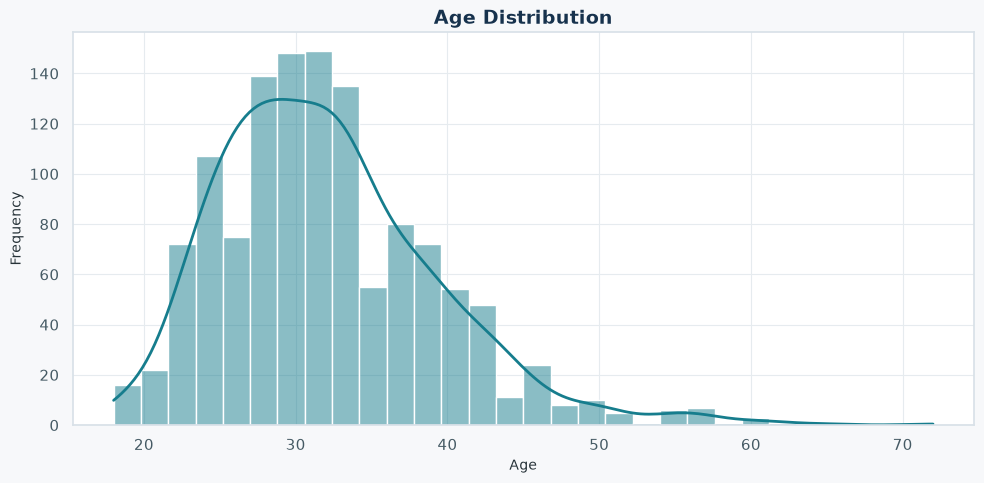

In [16]:
# Chart - 3 visualization code
plt.figure(figsize=(10,5))
sns.histplot(df['Age'], kde=True, bins=30, color='#167D8D', edgecolor='#FFFFFF', line_kws={'color': '#E07A5F', 'linewidth': 2})
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is appropriate for a numeric variable and helps reveal the age range, spread, and potential unusual values.

##### 2. What is/are the insight(s) found from the chart?

Describe the concentration and spread visible in the histogram and note any extreme values retained or removed during cleaning. This sample's age profile may not represent all tech workers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Describe the concentration and spread visible in the histogram and note any extreme values retained or removed during cleaning. This sample's age profile may not represent all tech workers.

#### Chart - 4

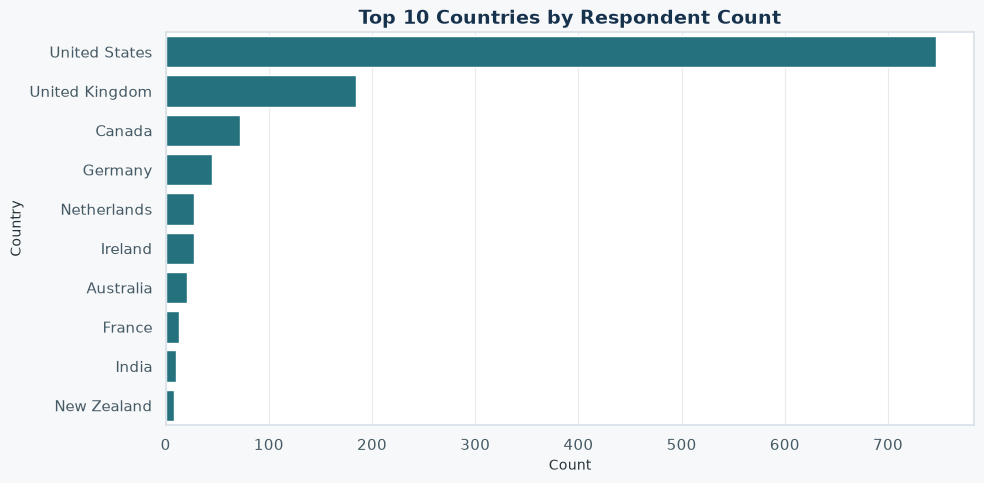

In [17]:
# Chart - 4 visualization code
top_countries = df['Country'].value_counts().head(10).index
plt.figure(figsize=(10,5))
sns.countplot(data=df, y='Country', order=top_countries, color='#167D8D')
plt.title('Top 10 Countries by Respondent Count')
plt.xlabel('Count')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal count plot keeps country labels readable and allows the most frequently represented countries to be compared.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies which countries contribute the most responses. High counts may reflect survey reach or participation, not a higher level of mental-health need.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The chart identifies which countries contribute the most responses. High counts may reflect survey reach or participation, not a higher level of mental-health need.

#### Chart - 5

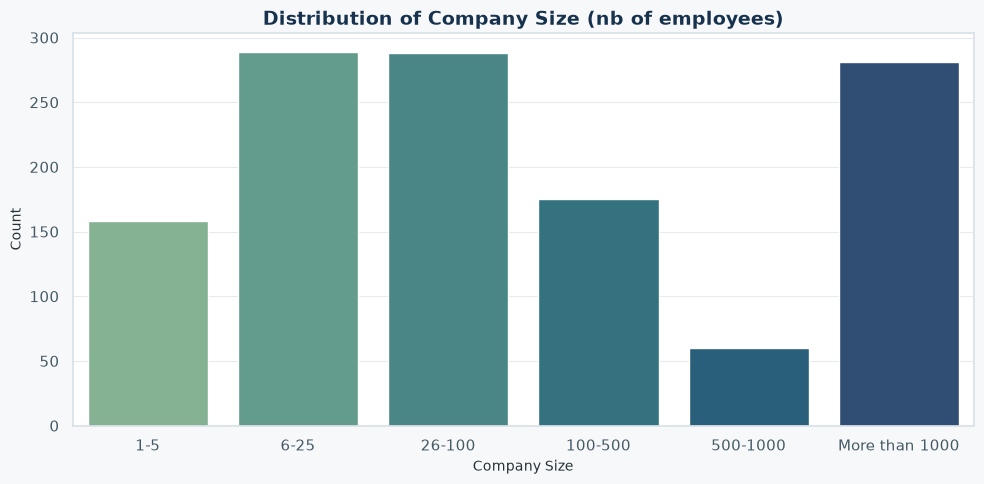

In [18]:
# Chart - 5 visualization code
order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='no_employees', order=order, palette='crest')
plt.title('Distribution of Company Size (nb of employees)')
plt.xlabel('Company Size')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot compares the employee-size categories and shows which company-size groups are most represented in the sample.

##### 2. What is/are the insight(s) found from the chart?

Describe the company-size categories with the most and fewest responses. These are survey response counts, not counts of companies or measures of mental-health outcomes by company size.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Describe the company-size categories with the most and fewest responses. These are survey response counts, not counts of companies or measures of mental-health outcomes by company size.

#### Chart - 6

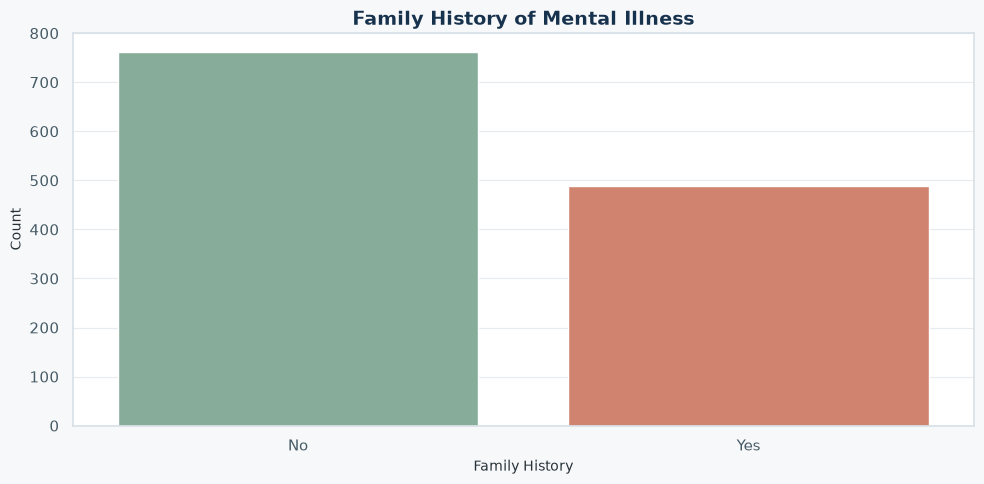

In [19]:
# Chart - 6 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='family_history', palette=['#81B29A', '#E07A5F'])
plt.title('Family History of Mental Illness')
plt.xlabel('Family History')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart summarizes the number of respondents reporting whether they have a family history of mental illness.

##### 2. What is/are the insight(s) found from the chart?

Compare the category counts in the chart. This variable provides context for later treatment-seeking comparisons but is not a diagnosis or a deterministic predictor for any individual.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Compare the category counts in the chart. This variable provides context for later treatment-seeking comparisons but is not a diagnosis or a deterministic predictor for any individual.

#### Chart - 7

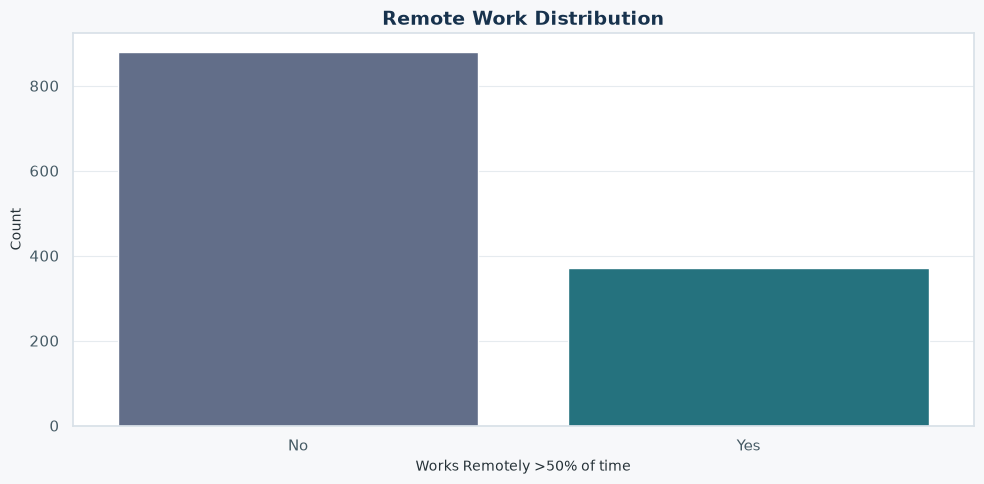

In [20]:
# Chart - 7 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='remote_work', palette=['#5B6C8F', '#167D8D'])
plt.title('Remote Work Distribution')
plt.xlabel('Works Remotely >50% of time')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot summarizes how many respondents report working remotely more than half the time versus those who do not.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the remote-work composition of this sample. It does not show whether remote work improves or worsens mental health.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

The chart shows the remote-work composition of this sample. It does not show whether remote work improves or worsens mental health.

#### Chart - 8

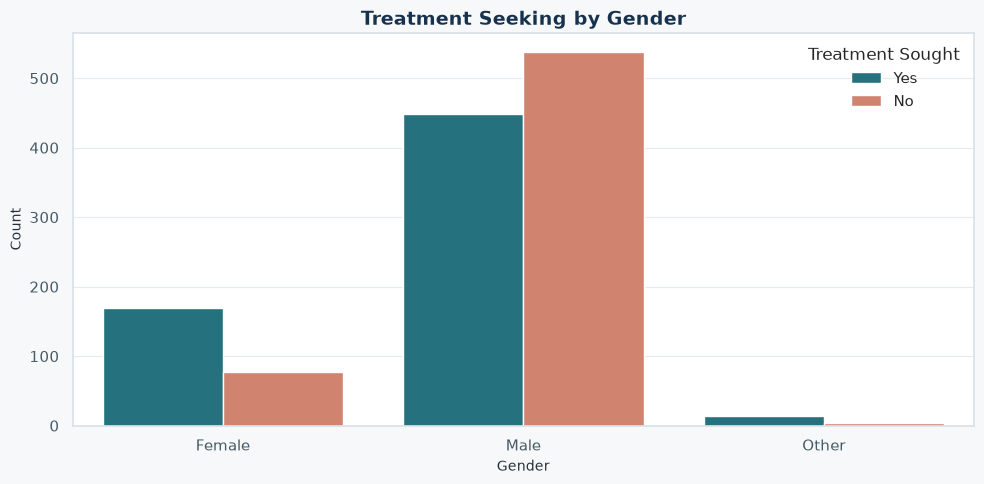

In [21]:
# Chart - 8 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Gender', hue='treatment', palette=['#167D8D', '#E07A5F'])
plt.title('Treatment Seeking by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Treatment Sought')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares treatment responses across gender categories in one view.

##### 2. What is/are the insight(s) found from the chart?

Compare treatment-response counts within each gender category, remembering that the groups may contain different numbers of respondents. Within-group percentages are more informative than raw counts alone.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Compare treatment-response counts within each gender category, remembering that the groups may contain different numbers of respondents. Within-group percentages are more informative than raw counts alone.

#### Chart - 9

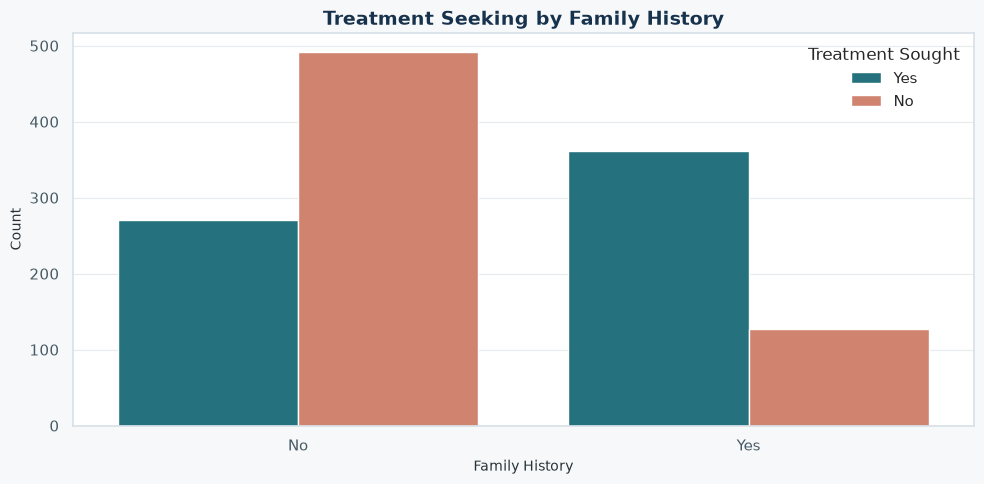

In [22]:
# Chart - 9 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='family_history', hue='treatment', palette=['#167D8D', '#E07A5F'])
plt.title('Treatment Seeking by Family History')
plt.xlabel('Family History')
plt.ylabel('Count')
plt.legend(title='Treatment Sought')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares treatment responses for respondents who do and do not report a family history.

##### 2. What is/are the insight(s) found from the chart?

Inspect how treatment-response counts differ between the family-history groups. Since group sizes may differ, within-group treatment percentages are more informative than raw counts; the chart shows association, not causation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Inspect how treatment-response counts differ between the family-history groups. Since group sizes may differ, within-group treatment percentages are more informative than raw counts; the chart shows association, not causation.

#### Chart - 10

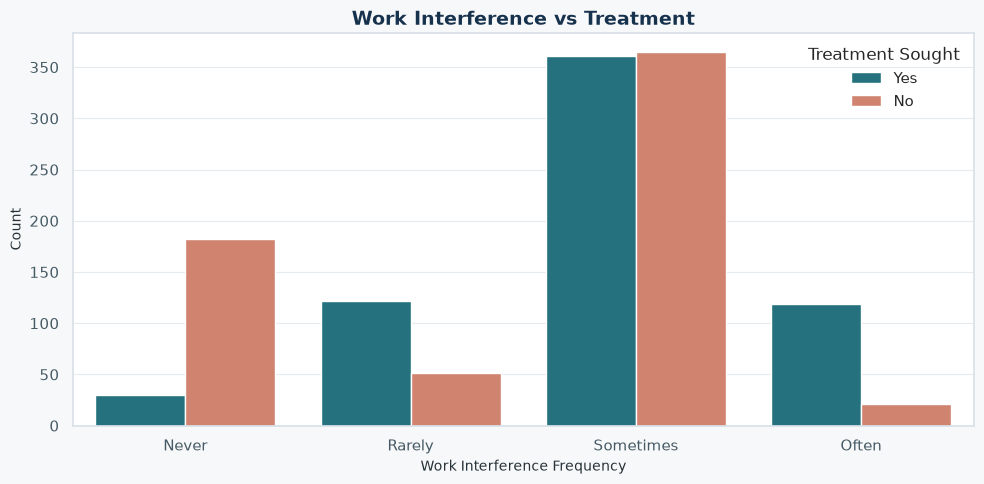

In [23]:
# Chart - 10 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='work_interfere', hue='treatment', order=['Never', 'Rarely', 'Sometimes', 'Often'], palette=['#167D8D', '#E07A5F'])
plt.title('Work Interference vs Treatment')
plt.xlabel('Work Interference Frequency')
plt.ylabel('Count')
plt.legend(title='Treatment Sought')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares treatment responses across reported levels of work interference.

##### 2. What is/are the insight(s) found from the chart?

Describe how the response distribution changes across work-interference categories. Check valid group sizes and percentages before concluding that one group is more likely to seek treatment.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Describe how the response distribution changes across work-interference categories. Check valid group sizes and percentages before concluding that one group is more likely to seek treatment.

#### Chart - 11

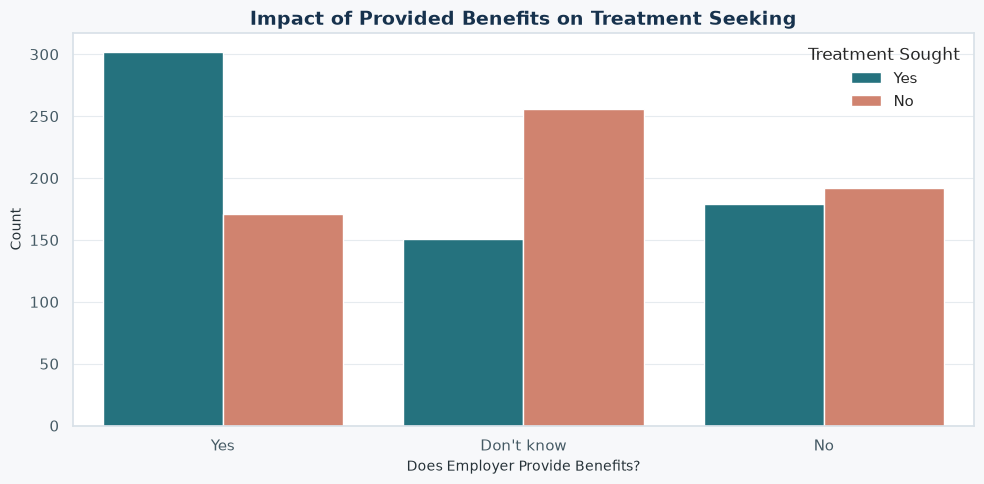

In [24]:
# Chart - 11 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='benefits', hue='treatment', palette=['#167D8D', '#E07A5F'])
plt.title('Impact of Provided Benefits on Treatment Seeking')
plt.xlabel('Does Employer Provide Benefits?')
plt.ylabel('Count')
plt.legend(title='Treatment Sought')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares treatment responses across answers about employer-provided mental-health benefits.

##### 2. What is/are the insight(s) found from the chart?

Use the bars to compare treatment responses by benefits category. Distinguish benefit availability from awareness or use, and consider within-category percentages because group sizes may differ.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Use the bars to compare treatment responses by benefits category. Distinguish benefit availability from awareness or use, and consider within-category percentages because group sizes may differ.

#### Chart - 12

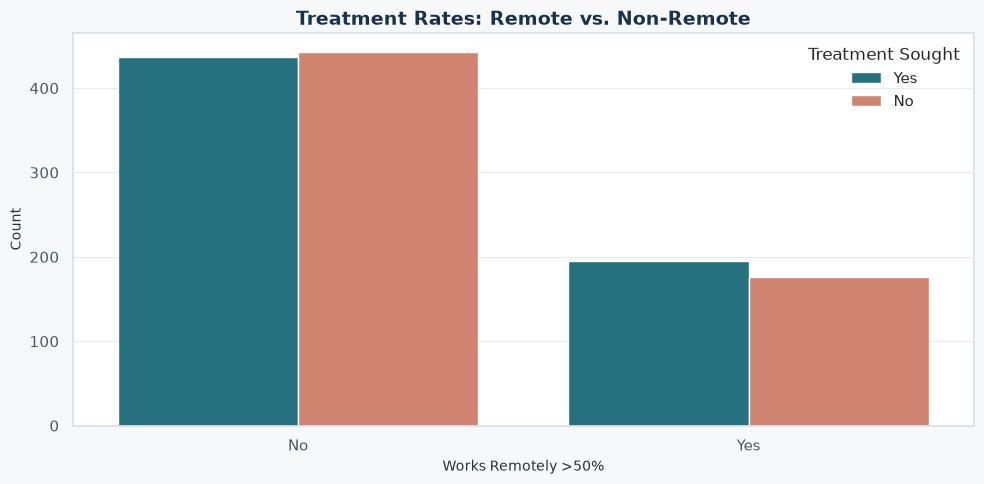

In [25]:
# Chart - 12 visualization code
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='remote_work', hue='treatment', palette=['#167D8D', '#E07A5F'])
plt.title('Treatment Rates: Remote vs. Non-Remote')
plt.xlabel('Works Remotely >50%')
plt.ylabel('Count')
plt.legend(title='Treatment Sought')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares treatment responses by reported remote-work arrangement.

##### 2. What is/are the insight(s) found from the chart?

Describe the response pattern for remote and non-remote groups. Raw counts may reflect different group sizes, so calculate within-group percentages before comparing likelihood.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Describe the response pattern for remote and non-remote groups. Raw counts may reflect different group sizes, so calculate within-group percentages before comparing likelihood.

#### Chart - 13

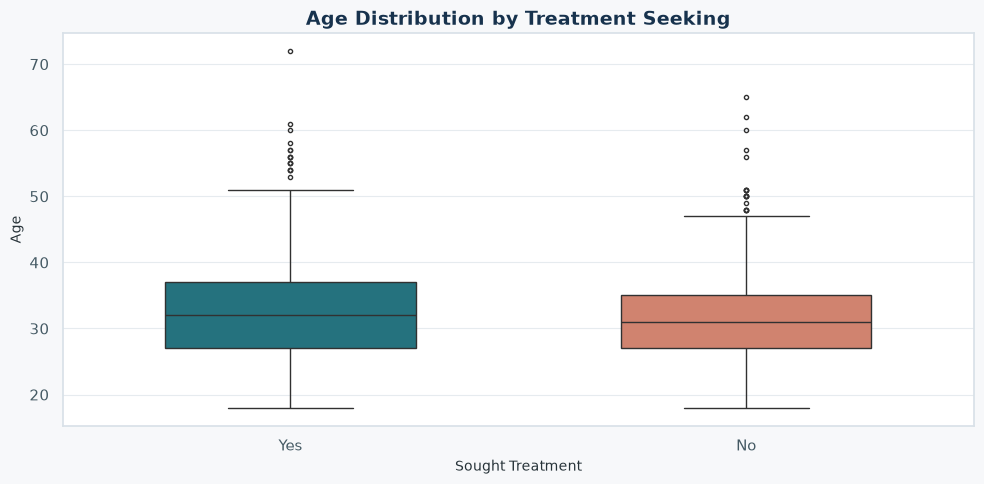

In [26]:
# Chart - 13 visualization code
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='treatment', y='Age', palette=['#167D8D', '#E07A5F'], width=0.55, fliersize=3)
plt.title('Age Distribution by Treatment Seeking')
plt.xlabel('Sought Treatment')
plt.ylabel('Age')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the age distributions of the two treatment-response groups and shows medians, spread, and potential outliers.

##### 2. What is/are the insight(s) found from the chart?

Compare the medians and interquartile ranges and note how much the distributions overlap. Any age difference is descriptive and does not imply that age causes treatment-seeking.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Compare the medians and interquartile ranges and note how much the distributions overlap. Any age difference is descriptive and does not imply that age causes treatment-seeking.

#### Chart - 14 - Correlation Heatmap

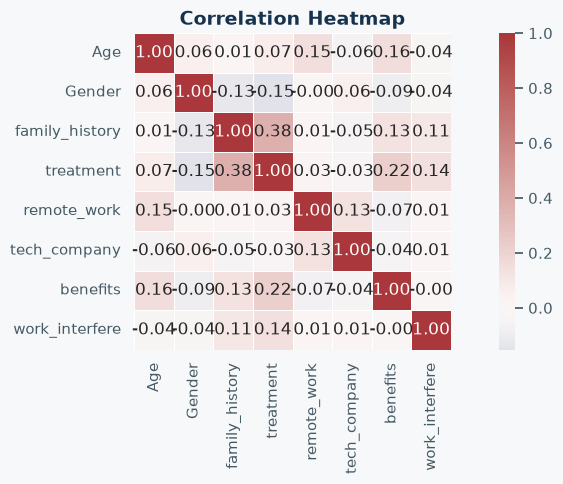

In [27]:
# Chart - 14 - Correlation Heatmap visualization code
# Encode binary/ordinal columns first, then heatmap
df_encoded = df.copy()
cols_to_encode = ['Gender', 'family_history', 'treatment', 'remote_work', 'tech_company', 'benefits', 'work_interfere']
for col in cols_to_encode:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

plt.figure(figsize=(10,5))
corr = df_encoded[['Age'] + cols_to_encode].corr()
sns.heatmap(corr, annot=True, cmap='vlag', center=0, fmt='.2f', linewidths=0.6, linecolor='#FFFFFF', square=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap gives a compact view of pairwise correlations among selected encoded variables and highlights relationships for further exploration.

##### 2. What is/are the insight(s) found from the chart?

Read the direction and strength of the displayed correlations, noting that numeric encoding of categories can affect interpretation. Correlation does not establish causation.

##### 3. Will the gained insights help create a positive business impact? Are there any risks?

Use the heatmap to identify questions for further investigation, not to make decisions based on correlation alone. Encoding choices and the observational nature of the survey limit interpretation.


#### Chart - 15 - Pair Plot

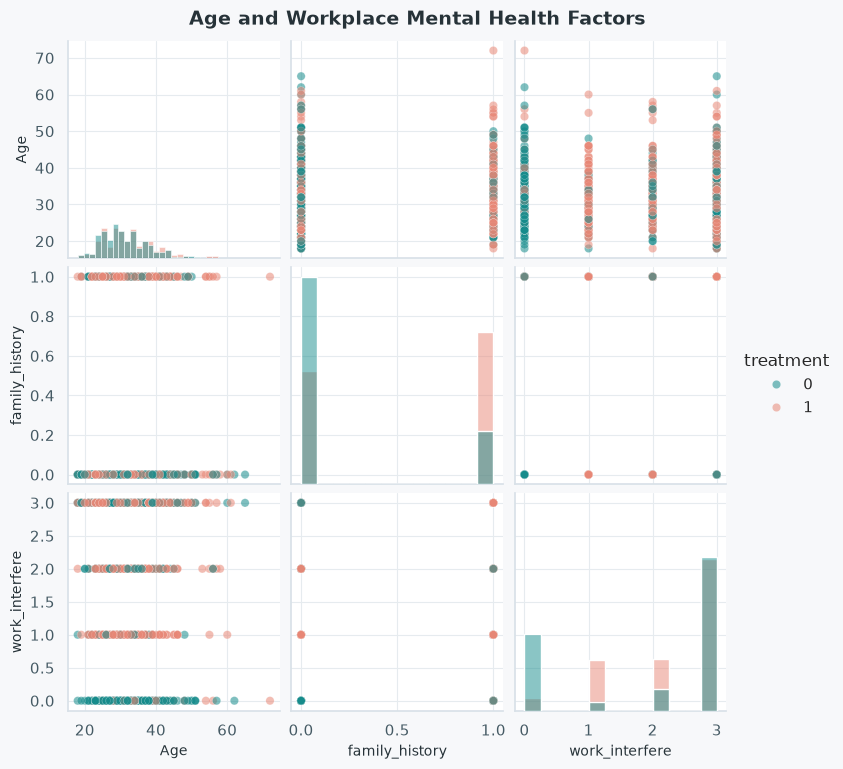

In [38]:
# Pair Plot — Calm Focus theme
vars_to_plot = [
    'Age',
    'treatment',
    'family_history',
    'work_interfere'
]

sns.pairplot(
    df_encoded[vars_to_plot].dropna(),
    hue='treatment',
    palette={
        0: '#168C8C',  # No — Teal
        1: '#E88776'   # Yes — Coral
    },
    diag_kind='hist',
    height=2.5,
    plot_kws={
        'alpha': 0.55,
        'edgecolor': 'white',
        'linewidth': 0.25
    }
)

plt.suptitle(
    'Age and Workplace Mental Health Factors',
    y=1.02,
    fontsize=14,
    fontweight='bold',
    color='#263238'
)

plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows pairwise distributions and relationships for the selected variables, helping identify patterns that may be missed in single charts.

##### 2. What is/are the insight(s) found from the chart?

Look for visible differences in distributions by treatment group and for overlap between groups. This is exploratory; overlapping patterns and encoded categorical variables limit the strength of conclusions.

##### 3. Will the gained insights help create a positive business impact? Are there any risks?

The pair plot can help select questions for deeper analysis, but it should not be used as a predictive or diagnostic tool. Apparent patterns should be checked with suitable summary statistics.


#### Chart - 16

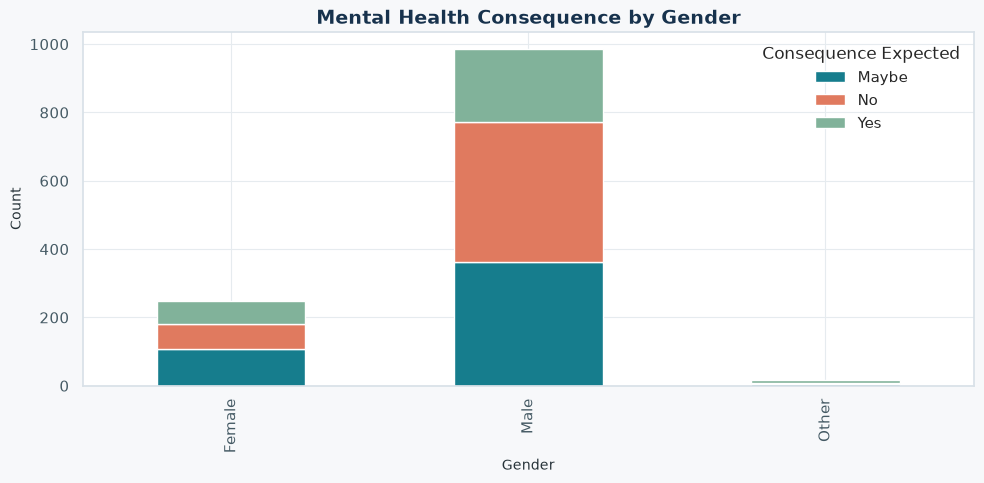

In [39]:
# Chart - 16 visualization code
# Stacked bar — mental_health_consequence vs Gender
consequence_ct = pd.crosstab(df['Gender'], df['mental_health_consequence'])
consequence_ct.plot(kind='bar', stacked=True, figsize=(10,5), color=['#167D8D', '#E07A5F', '#81B29A'])
plt.title('Mental Health Consequence by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Consequence Expected')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A stacked bar chart compares reported mental-health consequences across gender categories while showing the response composition.

##### 2. What is/are the insight(s) found from the chart?

Compare response categories within each gender group. Since group sizes can differ, within-group percentages or a 100% stacked chart may be easier to compare than raw counts.

##### 3. Will the gained insights help creating a positive business impact?

Compare response categories within each gender group. Since group sizes can differ, within-group percentages or a 100% stacked chart may be easier to compare than raw counts.

#### Chart - 17

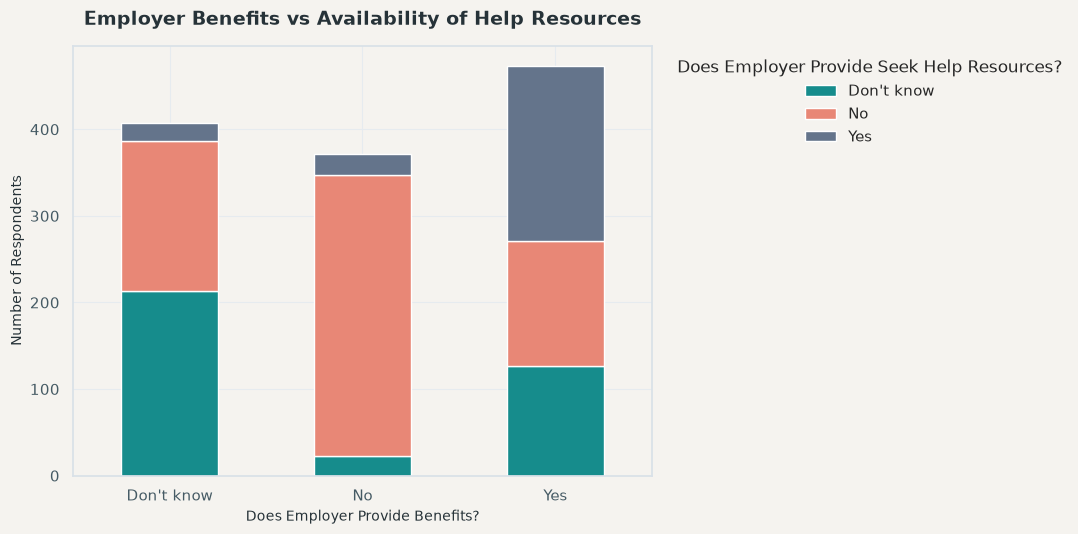

In [41]:

# Chart 17 — Stacked Bar: Seek Help vs Benefits
seekhelp_ct = pd.crosstab(df['benefits'], df['seek_help'])

ax = seekhelp_ct.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 5.5),
    color=['#168C8C', '#E88776', '#64748B']
)

ax.set_title(
    'Employer Benefits vs Availability of Help Resources',
    fontsize=14,
    fontweight='bold',
    color='#263238',
    pad=15
)
ax.set_xlabel('Does Employer Provide Benefits?', color='#263238')
ax.set_ylabel('Number of Respondents', color='#263238')

# Move legend outside the chart on the right
ax.legend(
    title='Does Employer Provide Seek Help Resources?',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.set_facecolor('#F5F3EF')
fig = ax.get_figure()
fig.patch.set_facecolor('#F5F3EF')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A stacked bar chart compares responses about employer benefits with responses about whether the employer encourages seeking help.

##### 2. What is/are the insight(s) found from the chart?

Inspect how encouragement-to-seek-help responses are distributed across benefits categories. The chart describes reported responses and does not prove that benefits cause encouragement.

##### 3. Will the gained insights help creating a positive business impact?

Inspect how encouragement-to-seek-help responses are distributed across benefits categories. The chart describes reported responses and does not prove that benefits cause encouragement.

#### Chart - 18

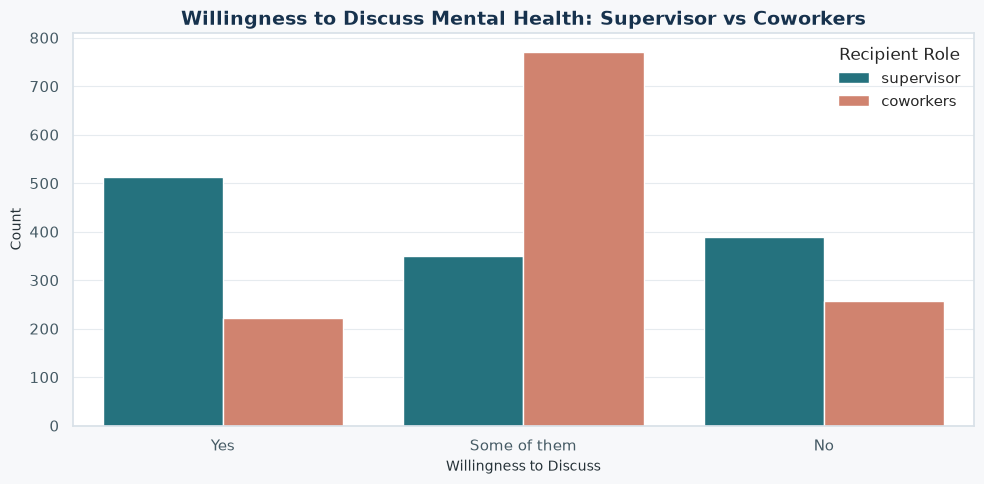

In [42]:
# Chart - 18 visualization code
# Grouped bar — supervisor vs coworkers
plt.figure(figsize=(10,5))
# Need to melt to compare responses on same scale
df_melted = df.melt(value_vars=['supervisor', 'coworkers'], var_name='recipient', value_name='willingness')
sns.countplot(data=df_melted, x='willingness', hue='recipient', order=['Yes', 'Some of them', 'No'], palette=['#167D8D', '#E07A5F'])
plt.title('Willingness to Discuss Mental Health: Supervisor vs Coworkers')
plt.xlabel('Willingness to Discuss')
plt.ylabel('Count')
plt.legend(title='Recipient Role')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares reported willingness to discuss mental health with coworkers versus supervisors on a shared response scale.

##### 2. What is/are the insight(s) found from the chart?

Compare the response distributions for coworkers and supervisors, including positive, negative, and neutral responses. Check category ordering and sample sizes before summarizing the pattern.

##### 3. Will the gained insights help creating a positive business impact?

Compare the response distributions for coworkers and supervisors, including positive, negative, and neutral responses. Check category ordering and sample sizes before summarizing the pattern.

#### Chart - 19

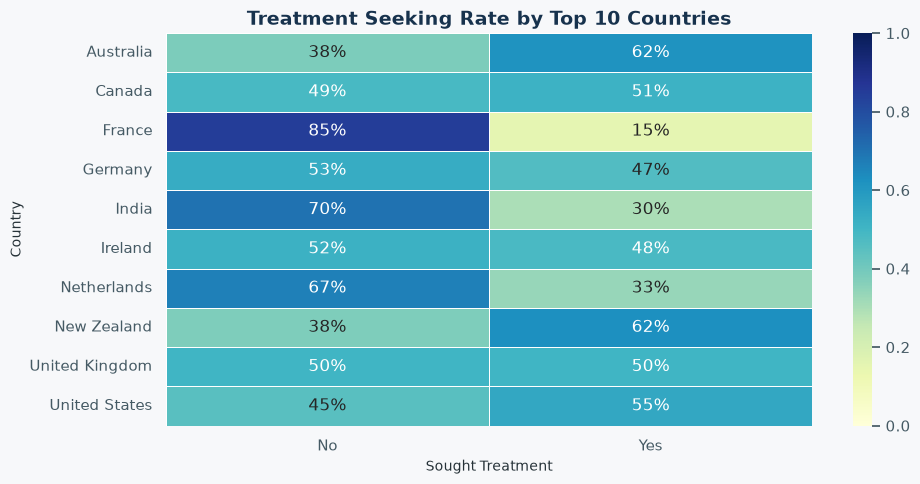

In [43]:
# Chart - 19 visualization code
# Heatmap — treatment rate by top 10 Countries (pivot table)
df_top10 = df[df['Country'].isin(top_countries)]
pivot = df_top10.pivot_table(index='Country', columns='treatment', aggfunc='size', fill_value=0)
pivot_prob = pivot.div(pivot.sum(axis=1), axis=0)
plt.figure(figsize=(10,5))
sns.heatmap(pivot_prob, annot=True, cmap='YlGnBu', vmin=0, vmax=1, fmt='.0%', linewidths=0.6, linecolor='#FFFFFF')
plt.title('Treatment Seeking Rate by Top 10 Countries')
plt.xlabel('Sought Treatment')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of within-country treatment-response proportions makes comparisons among the most represented countries easier than raw counts alone.

##### 2. What is/are the insight(s) found from the chart?

Use the cell values and color scale to compare proportions among selected countries. Small or uneven samples can make apparent differences unstable, and these countries do not represent every country.

##### 3. Will the gained insights help creating a positive business impact?

Use the cell values and color scale to compare proportions among selected countries. Small or uneven samples can make apparent differences unstable, and these countries do not represent every country.

#### Chart - 20

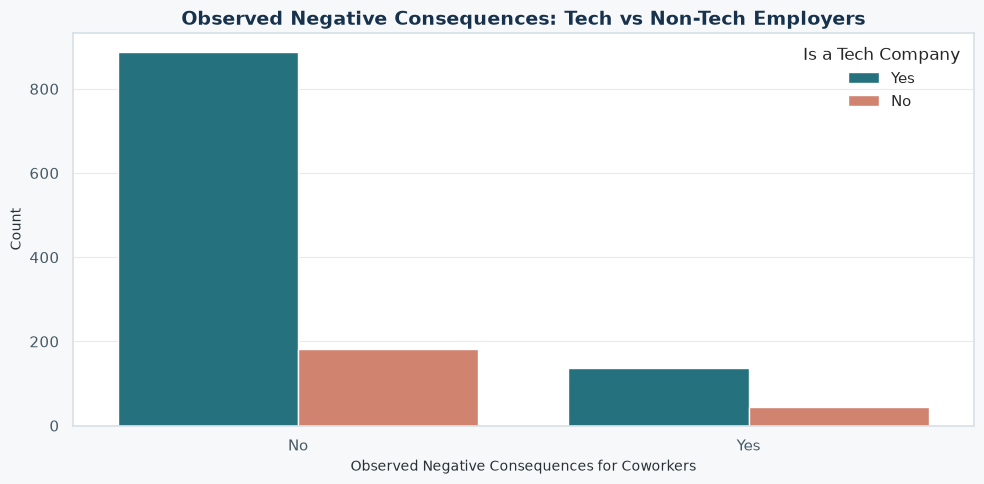

In [44]:
# Chart - 20 visualization code
# Count plot — obs_consequence by tech_company
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='obs_consequence', hue='tech_company', palette=['#167D8D', '#E07A5F'])
plt.title('Observed Negative Consequences: Tech vs Non-Tech Employers')
plt.xlabel('Observed Negative Consequences for Coworkers')
plt.ylabel('Count')
plt.legend(title='Is a Tech Company')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot compares reported observed negative consequences across respondents at tech and non-tech companies.

##### 2. What is/are the insight(s) found from the chart?

Describe how response categories differ between the two employer groups. The plot captures respondents' reports and perceptions; it does not establish actual incidence or causation.

##### 3. Will the gained insights help creating a positive business impact?

Describe how response categories differ between the two employer groups. The plot captures respondents' reports and perceptions; it does not establish actual incidence or causation.

## Chart 21: Global Distribution of Mental Health Survey Responses

This choropleth map shows the geographical distribution of respondents
in the Mental Health in Tech survey. It helps identify which countries
contributed the most responses and highlights gaps in geographical coverage.

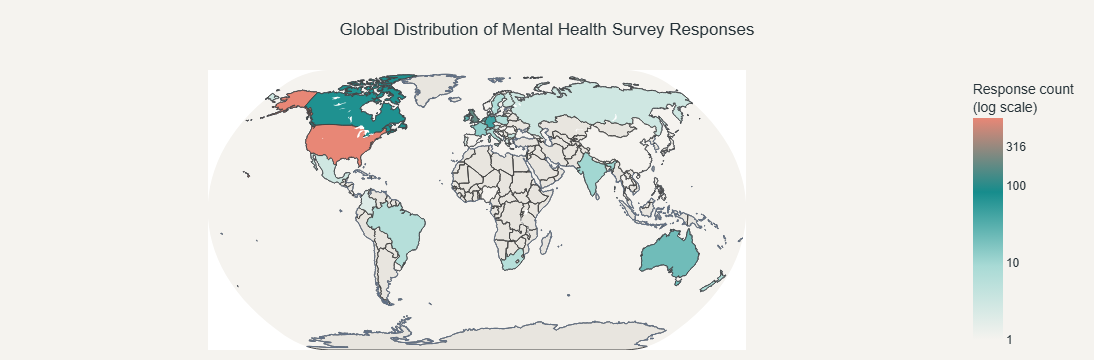

In [45]:
import plotly.express as px
import numpy as np

country_counts = (
    df['Country']
    .value_counts()
    .rename_axis('Country')
    .reset_index(name='Respondents')
)

# Log scale makes smaller country counts more visible
country_counts['Log Respondents'] = np.log10(
    country_counts['Respondents']
)

fig = px.choropleth(
    country_counts,
    locations='Country',
    locationmode='country names',
    color='Log Respondents',
    hover_name='Country',
    hover_data={
        'Respondents': True,
        'Log Respondents': False
    },
    color_continuous_scale=[
        '#F5F3EF',
        '#A8DAD5',
        '#168C8C',
        '#E88776'
    ],
    title='Global Distribution of Mental Health Survey Responses'
)

fig.update_layout(
    paper_bgcolor='#F5F3EF',
    font=dict(color='#263238', family='Arial'),
    title_x=0.5,
    coloraxis_colorbar=dict(
        title='Response count<br>(log scale)',
        tickvals=[0, 1, 2, 2.5],
        ticktext=['1', '10', '100', '316']
    ),
    geo=dict(
        projection_type='natural earth',
        showframe=False,
        showcoastlines=True,
        coastlinecolor='#64748B',
        showcountries=True,
        showland=True,
        landcolor='#E8E5DF',
        showocean=True,
        oceancolor='#F5F3EF'
    ),
    margin=dict(l=10, r=10, t=70, b=10)
)

fig.show()

### Chart Interpretation

**1. Why did I choose this chart?**

I chose a choropleth map because it visually represents the geographical distribution of survey respondents. It makes it easier to compare participation across countries.

**2. What insights did I find?**

The United States contributed the highest number of responses, followed by the United Kingdom and Canada. The responses are concentrated in a relatively small number of countries, while several countries have much lower participation.

**3. Can these insights create a positive business impact?**

Yes. Organizations conducting future workplace mental health surveys can use these findings to identify where additional data collection is needed and improve geographical representation before making broader decisions.

**4. Are there any negative-growth insights or limitations?**

The uneven distribution of responses may introduce geographical bias. The map represents the number of survey responses, not the prevalence of mental health conditions in each country. Therefore, the results should not be generalized to entire national workforces without more representative data.

## **5. Solution to Business Objective**

The charts provide a descriptive view of the survey respondents and allow treatment-seeking responses to be compared with selected personal and workplace variables. The practical business value is a shortlist of questions for employers to investigate: whether support benefits are known and accessible, whether employees feel safe discussing mental health, and whether remote and on-site employees can access the same resources.

Before finalizing findings, run every chart and record specific observations from the outputs. Where possible, compare within-group percentages as well as counts. The survey is observational and self-reported, so results should be treated as associations rather than causal evidence.

1. **Destigmatize Care Access:** Build broad campaigns dissolving fears of negative consequence around revealing conditions, a major bottleneck across all genders.
2. **Over-communicate Coverage Channels:** Given that knowledge of benefits vastly outpaces pure ignorance in routing employees to care, HR must weave benefit literacy aggressively into regular communication cycles, not just singular onboarding blocks.
3. **Train Middleware Leadership:** Middle managers and supervisors are demonstrably prioritized as confidantes over lateral peer coworkers; they require significant sensitivity and behavioral triage training.
4. **Localize Mental Health Frameworks:** Leverage entirely different campaigns for geospatially diverse offices since regions severely differ in clinical treatment baselines.
5. **Identify Work Thresholds:** Continuously monitor workloads because "work interference" holds the tightest clustering parameter aligned with someone requiring formal psychological intervention.
6. **Preventative Targeting:** Because family history anchors the highest predictability metric, confidentially offer pre-emptive screenings specifically aimed towards populations harboring historical behavioral risks.

# **Conclusion**

This exploratory analysis examines how treatment-seeking responses and workplace perceptions vary across the survey sample. The visualizations investigate family history, work interference, employer benefits, work arrangements, and perceived workplace consequences. The strength and direction of each pattern should be confirmed from the rendered charts and, where relevant, within-group percentages.

From a business perspective, the findings can generate practical follow-up questions about benefit awareness, confidential access to support, manager communication, and employees' concerns about negative consequences. They should not be used to diagnose employees, predict an individual's mental health, or claim that any single factor causes treatment-seeking.